In [1]:
#utils
import pandas as pd
import numpy as np

#visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

#machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, auc
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import precision_recall_curve



In [2]:
df = pd.read_csv('SimData.csv')
df = df.head(300)

In [3]:
#this gives us the duimension of the dataset we're working with.
df.shape

(300, 9)

qop stands for "charge-to-over-momentum" ratio, is a measure of the electric charge of a particle relative to its momentum

In [4]:
target_feature = "isghost"
#instantiate two more datasets one to contain the normal data
#and the other to hold the anomalous instances
normal_data = df[df[target_feature] == 0].drop(columns=target_feature)
anomalous_data = df[df[target_feature] == 1].drop(columns=target_feature)

#also instantiate a dataframe to carry all the features
#and a second one to instead contain the target variable
features = df.drop([target_feature], axis=1)
label = df[target_feature]

#the stratify parameter here is set to be "isghost" meaning that the 
#proportions of ghost and normal tracks in both train and test datasets
#will be kept the same...
x_train, x_test, y_train, y_test = train_test_split(
    features, label, test_size=0.2, stratify=label
)

#remember that at least for the autoencoders we're gonna use just the 
#normal instances during the training phase so we have to filter those in x_train
train_index = y_train[y_train == 0].index
train_normal_data = x_train.loc[train_index]

In [5]:
#here I need to rescale the data as the featurea have different ranges 


#Don't forget that testing data points represent real-world data.
#Feature normalization (or data standardization) of the explanatory (or predictor) variables
#is a technique used to center and normalise the data by subtracting the mean and dividing by the variance.
#If you take the mean and variance of the whole dataset you'll be introducing future information
#into the training explanatory variables (i.e. the mean and variance).

#Therefore, you should perform feature normalisation over the training data.
#Then perform normalisation on testing instances as well, but this time using the mean and variance
#of training explanatory variables. In this way, we can test and evaluate
#whether our model can generalize well to new, unseen data points.

#creating a scaler and decing which columns to process
train_normal_data = (train_normal_data - train_normal_data.mean()) / train_normal_data.std()
x_test = (x_test - train_normal_data.mean()) / train_normal_data.std()

#now moving the data to a fixed range of values 
scaler = MinMaxScaler()

train_normal_data = scaler.fit_transform(train_normal_data)
x_test = scaler.fit_transform(x_test)

train_normal_data

array([[0.00809999, 0.52941176, 0.44457816, ..., 0.33752728, 0.24118907,
        0.15692347],
       [0.00302353, 0.47058824, 0.44305927, ..., 0.33713096, 0.24321103,
        0.40159187],
       [0.01485175, 0.17647059, 0.75331698, ..., 0.3456876 , 0.24453581,
        0.26610644],
       ...,
       [0.01104347, 0.29411765, 0.1767928 , ..., 0.48072464, 0.31719611,
        0.41332   ],
       [0.00279594, 0.29411765, 0.38476407, ..., 0.3354534 , 0.24115743,
        0.1674849 ],
       [0.00543158, 0.47058824, 0.47209624, ..., 0.33522006, 0.24223684,
        0.28810473]])

# Visualization

<Axes: >

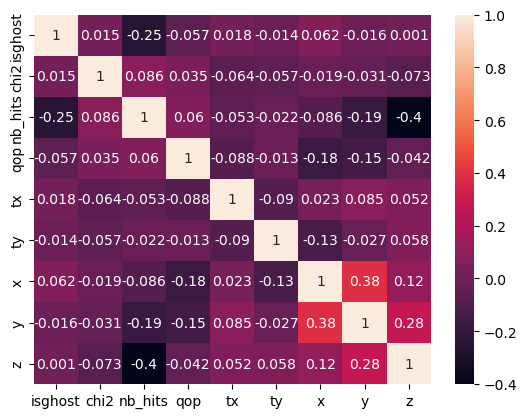

In [6]:
corr = df.corr().round(3)
sns.heatmap(corr, annot=True)

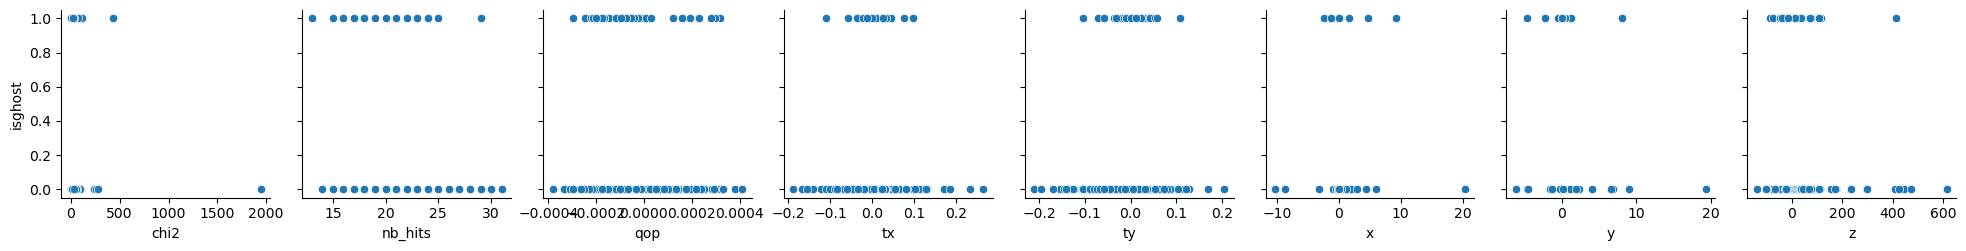

In [7]:
sns.pairplot(data=df, x_vars= df.drop(columns=target_feature).columns, y_vars=[target_feature])

plt.show()

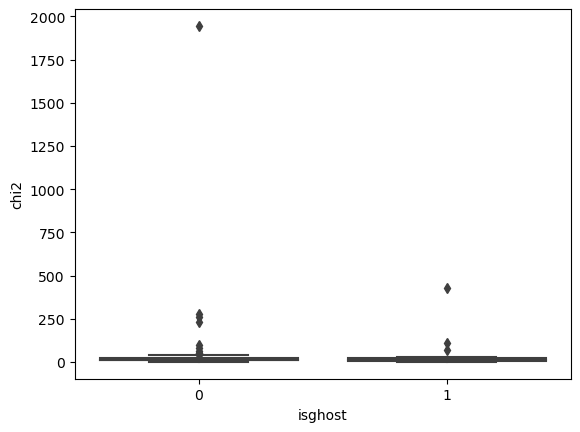

In [8]:
sns.boxplot(x=target_feature, y='chi2', data=df)

plt.show()

# Model Fitting

In [9]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score
from models.AutoEncoder import Autoencoder
from models.ContractiveAutoEncoder import ContractiveAutoEncoder
from models.vae import VariationalAutoEncoder


#instantiate the contractive autoencoder
#the input dimension should match with the input features
#instead the latent dimensionis the desired compression rate
#such that higher latent_dim result in lower compression rate and more expressivity
#while instead lower latent dimension leads to less reconstruction quality
# but also less validatinon error (less model complexity)

#The latent space representation captures the most salient features of the input data
#a lower latent_dim may lead to a higher reconstruction error for anomalous inputs,
#setting latent_dim too low may also result in the loss of important information
#latent dimension should start small and then raised until diminishing returns 


#when performing anomaly detection using autoencoders these have to be trained using normal data
#such that the network learns to reproduce those instances, and that we can then perform the 
#detection using a threshold applied on the reconstruction error of any instance
input_dim = normal_data.shape[1]
latent_dim = 3
learning_rate = 0.001
epochs = 1

#vae = VariationalAutoEncoder(input_dim=input_dim, encoding_dim=latent_dim, learning_rate=learning_rate)
cae = ContractiveAutoEncoder(input_dim=input_dim, encoding_dim=latent_dim, lambda_= 0.01, learning_rate=learning_rate)
cae.build(input_shape=(train_normal_data.shape))
ae = Autoencoder(input_dim=input_dim, encoding_dim=latent_dim, learning_rate=learning_rate)
ae.build(input_shape=(train_normal_data.shape))


In [10]:
#history_vae = vae.train(train_normal_data, epochs=epochs, batch_size=128, validation_split=0.2)


In [11]:
#start the training of the NN,
#assuming a convex loss function the higher the number of epochs the better the results will be.
#an higher batch size implies that a larger share of the training examples are processed together
#this eventually leads to fatser training and higher generalizion error (model doesn't learn underlying distribution but training data) 
history_cae = cae.train(train_normal_data, num_epochs=epochs, batch_size=30)


TypeError: in user code:

    File "c:\Users\carlo\Desktop\anomaly detection\models\ContractiveAutoEncoder.py", line 181, in train  *
        x_train, x_val = train_test_split(x_train, test_size=0.2)
    File "d:\programs\conda\envs\macchina\lib\site-packages\sklearn\model_selection\_split.py", line 2586, in train_test_split  *
        chain.from_iterable(
    File "d:\programs\conda\envs\macchina\lib\site-packages\sklearn\utils\__init__.py", line 356, in _safe_indexing  *
        return _array_indexing(X, indices, indices_dtype, axis=axis)
    File "d:\programs\conda\envs\macchina\lib\site-packages\sklearn\utils\__init__.py", line 185, in _array_indexing  *
        return array[key] if axis == 0 else array[:, key]

    TypeError: Only integers, slices (`:`), ellipsis (`...`), tf.newaxis (`None`) and scalar tf.int32/tf.int64 tensors are valid indices, got array([ 48,  68,  99,   9, 204, 186,  73,   1,  75, 118,  27,  20,  23,
             3, 172,  98, 214,  63, 123,  28, 148, 159, 183,

In [ ]:
history_ae = ae.train(train_normal_data, epochs=epochs, batch_size=30, validation_split=0.2)

Train on 172 samples, validate on 44 samples
 30/172 [====>.........................] - ETA: 6s - loss: 0.0574

d:\programs\conda\envs\macchina\lib\site-packages\keras\engine\training_v1.py:2332: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates = self.state_updates


172/172 [==============================] - 2s 10ms/sample - loss: 0.0588 - val_loss: 0.0574


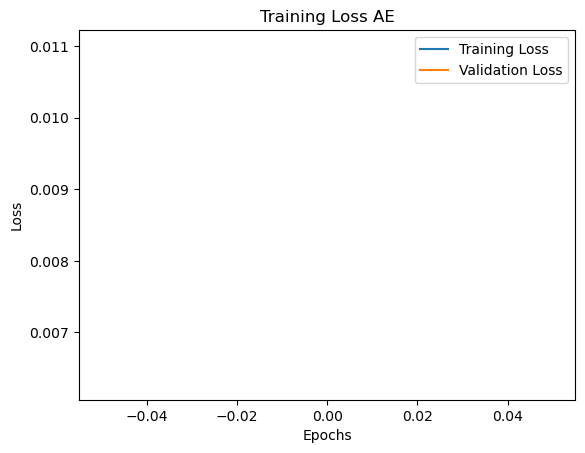

In [ ]:
# plot the training a val loss over the epochs fro the naive autoencoder
plt.plot(history_ae.history['loss'], label='Training Loss')
plt.plot(history_ae.history['val_loss'], label='Validation Loss')
# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss AE')

# Add legend
plt.legend()

# Display the plot
plt.show()

In [ ]:
"""# plot the training a val loss over the epochs fro the naive autoencoder
plt.plot(history_vae.history['loss'], label='Training Loss')
plt.plot(history_vae.history['val_loss'], label='Validation Loss')
# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss VAE')

# Add legend
plt.legend()

# Display the plot
plt.show()"""

NotImplementedError: Cannot convert a symbolic tf.Tensor (Mean_520:0) to a numpy array. This error may indicate that you're trying to pass a Tensor to a NumPy call, which is not supported.

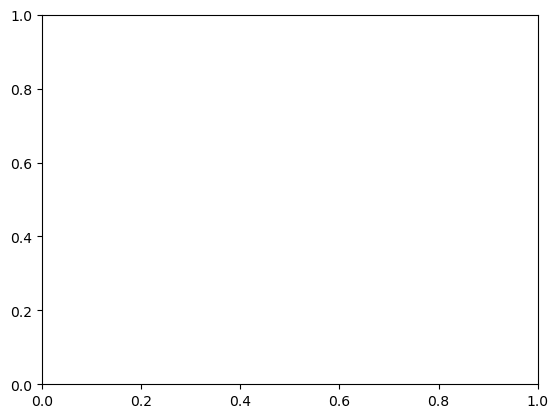

In [ ]:
#contractive loss training and validation loss
train_losses = [item[0] for item in history_cae]
val_losses = [item[1] for item in history_cae]
epochs = range(1, len(history_cae)+1)

plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title('Training and Validation Loss CAE')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
#MAE of the CAE over the number of samples 
cae_train_pred, _ = cae.call(train_normal_data)
cae_mae_loss = np.mean(np.abs(cae_train_pred - train_normal_data), axis=1)

#MAE of the AE over the number of samples 
ae_train_pred = ae.predict(train_normal_data)
ae_mae_loss = np.mean(np.abs(ae_train_pred - train_normal_data), axis=1)

#MAE of the VAE over the number of samples 
#vae_train_pred = vae.predict(train_normal_data)
#vae_mae_loss = np.mean(np.abs(vae_train_pred - train_normal_data), axis=1)

# Plotting
plt.hist(ae_mae_loss, alpha= 0.5, label='AE', bins=50)
plt.hist(cae_mae_loss, alpha= 0.5, label='CAE', bins=50)
#plt.hist(vae_mae_loss, alpha= 0.5, label='CAE', bins=50)

# Add labels and title
plt.xlabel('Number of Samples')
plt.ylabel('Training Loss')
plt.title('Training Loss Comparison')

# Add legend
plt.legend()

# Display the plot
plt.show()

# Setting a threshold
In anomaly detection, a threshold is used to determine whether a sample is normal or anomalous based on its reconstruction error (i.e., the difference between the input and its reconstruction).

The threshold is typically set by selecting a value such that any sample with a reconstruction error above the threshold is classified as an anomaly, while any sample with a reconstruction error below the threshold is classified as normal. To come up with said thrashold we're going to take the mean and standard deviation of the residuals, and cosnidering a number of standard deviations away from the mean we're gonna find a threshold. 
The threshold needs to be set on the reconstruction for the training and not for the test as that would introduce some information on the underlying distribution of the data.

In [ ]:
# TAKES 9 MIN FOR 4 METHOD CALLS 
#percentile_treshold_cae = cae.find_best_percentile_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
deviations_threshold_cae = cae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
#percentile_treshold_ae = ae.find_best_percentile_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)
deviations_threshold_ae = ae.find_best_deviations_threshold(x_train=train_normal_data, x_test=x_test, y_test=y_test)

In [ ]:
#getting 
predictions_ae = ae.find_anomalies(x_test, deviations_threshold_ae)

#looking at the metrics for anomaly detection so far
ae.print_classification_metrics(y_test, predictions_ae)

In [ ]:
#getting the predictions
predictions_cae = cae.find_anomalies(x_test, deviations_threshold_cae)

#looking at the metrics for anomaly detection so far
cae.print_classification_metrics(y_test, predictions_cae)

In [ ]:
#getting the predictions
#predictions_vae = vae.find_anomalies(x_test, deviations_threshold_cae)

#looking at the metrics for anomaly detection so far
#vae.print_classification_metrics(y_test, predictions_cae)

# Performance 

Here we're going to take into consideration some metrics, with their relevant visualization, of the models' performance in the anomaly detectino task. 
As first step we're so going to look into the ROC curve, that is a plot of the "False positive rate" against the "True positive rate". The curve therefore aims at 
describing the strength of a classifier, such that the more the curve appriaches the top left corner the strongest the method is. While instead if the curve approaches the 
line y = x, or the corss-section of the plane, the more the classifier approaches a random one. 

In [ ]:
def plot_ROC(y_test, predictions):

    # find the roc curve for the actual target values and the predictions
    fpr, tpr, _ = roc_curve(y_test, predictions)
    roc_auc = auc(fpr, tpr)

    #finding the Youden's J statistic, it's a metric that describes the power of classifier
    #where 0 is random guesser and 1 is a perfect classifier
    j_statistic = tpr - fpr
    print("the j_statistic is " + str(j_statistic[1]))

    #plotting the roc curve with the best trehsold against the random predictor
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc="lower right")
    plt.show()


In [ ]:
plot_ROC(y_test=y_test, predictions=predictions_ae)

In [ ]:
plot_ROC(y_test=y_test, predictions=predictions_cae)

In [ ]:
#plot_ROC(y_test=y_test, predictions=predictions_vae)

### Precision recall curve

This type of plot is made to better understand the performance of the models, given an high class imbalance. Precision indicates the proportion of correct positive identifications. Recall instead the proportion of actual positives that has been identified correctly. 

In [ ]:
def pr_curve(y_true, predictions):

    precision, recall, _ = precision_recall_curve(y_true, predictions)

    # plot the precision-recall curve
    plt.plot(recall, precision)
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.show()

In [ ]:
pr_curve(y_test, predictions_ae)

In [ ]:
pr_curve(y_test, predictions_cae)

In [ ]:
"""pr_curve(y_test, predictions_vae)"""

### Latent space plot.

Here we investigate how the ghost and normal samples are separated by the different models in the latent space. Eventually we would like to have the ghost tracks clustered together and so the normal ones. The normal tracks will be shown in green and the ghost tracks in red. 

In [ ]:
#visualizing the latent space !!!!!!!!!!!!!!!!
#this works in 2-3 dimensions...to do this sort of visualization 
#use latent space 2/3D

def plot_latent(name, model):

    latent_representation = model.encode(train_normal_data)
    X = latent_representation[:,0]
    y = latent_representation[:,1]
    z = latent_representation[:,2]
    # plotting
    plt.subplots(figsize=(8, 8))
    plt.scatter(X[y_train==0], y[y_train==0], z[y_train==0], s=1, c='g', alpha=0.3, label='Normal')
    plt.scatter(X[y_train==1], y[y_train==1], z[y_train==1], s=2, c='r', alpha=0.7, label='Ghost')

    # labeling
    plt.legend(loc='best')
    plt.title('Latent Space Representation from model ' + name)

    # saving & displaying
    plt.savefig('latent_representation_2d');
    plt.show()

In [ ]:
plot_latent("AE", ae)

In [ ]:
plot_latent("CAE", cae)

In [ ]:
""""plot_latent("VAE", vae)"""

### Reconstruction error 

Here I'm plotting the reconstruction error distribution of the different methods so to have a overview of their "strength" and point out eventual discrepancies.

In [ ]:
def plot_reconstruction_error(errors): 
    
    normal = errors[y_test==0]
    ghost = errors[y_test==1]

    _, ax = plt.subplots(figsize=(8,8))

    ax.hist(normal, bins=50, density=True, label="Normal", alpha=0.6)
    ax.hist(ghost, bins=50, density=True, label="Ghost", alpha=0.6)

    plt.title("(Normalized) Distribution of the Reconstruction Loss")
    plt.legend()
    plt.show()

In [ ]:
mse = np.mean(np.power(x_test - predictions_ae, 2), axis=1)
plot_reconstruction_error(mse)

In [ ]:
mse = np.mean(np.power(x_test - predictions_cae, 2), axis=1)
plot_reconstruction_error(predictions_cae)

In [ ]:
"""mse = np.mean(np.power(x_test - predictions_vae, 2), axis=1)
plot_reconstruction_error(mse)"""

# ALAD
#### First we're gonna transfer the weights of the encoder part of the autoencoder to the generator of the ALAD

In [ ]:
from ALAD import ALAD
from sklearn.metrics import accuracy_score


latent_dim = train_normal_data.shape[1]
anomaly_detector = ALAD(input_dim=train_normal_data.shape[1], latent_dim=latent_dim, learning_rate=0.003)

# the model needs to be trained on the normal data to learn the underlying distribution
anomaly_detector.train(train_normal_data, num_epochs=1, batch_size=64)

predictions = anomaly_detector.predict(x_test)


# here we're relying on a threshold set just based on the percentile
threshold = np.percentile(predictions, 95)

predictions = np.where(predictions > threshold, 1, 0)

#print the accuracy and the roc
accuracy = accuracy_score(y_test, predictions)
print('Accuracy of anomaly detection: {:.2f}%'.format(accuracy * 100))

d:\programs\conda\envs\macchina\lib\site-packages\tensorflow_addons\utils\tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


KeyboardInterrupt: 

the j_statistic is 0.0


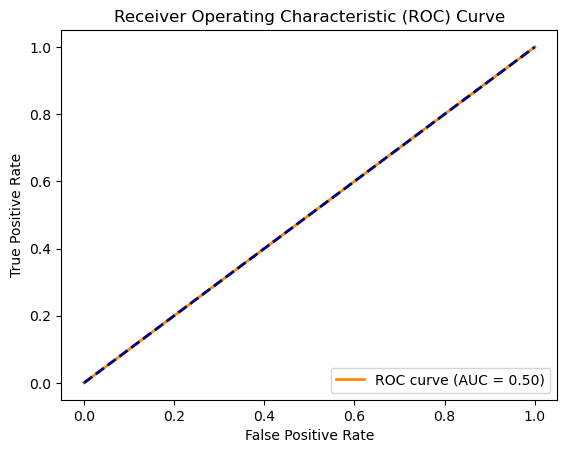

In [ ]:
plot_ROC(y_test=y_test, predictions=predictions)

In [ ]:
# Step 1: Extract encoder weights from pre-trained autoencoder
#pretrained_autoencoder = ca.encoder  # Replace with your pre-trained autoencoder model
# Extract encoder weights (e.g., the first half of the autoencoder model)
#encoder_weights = pretrained_autoencoder.layers[:len(pretrained_autoencoder.layers)//2].get_weights()

# Step 2: Create generator model and initialize with encoder weights
#generator = alad.genator  # Replace with your ADAL generator model
# Add generator layers with the same architecture as the ADAL generator
# Set the weights of the generator's layers with the extracted encoder weights
#for i, layer in enumerate(generator.layers):
#    if isinstance(layer, Dense):
#        layer.set_weights(encoder_weights[i*2:i*2+2])

# Isolation forest

In [ ]:
#this is an unsupervised learning method,
#in fact it is fed both normal and anomalous data
#during the training phase it learns from both normal and anomalous



from sklearn.ensemble import IsolationForest

# Step 1: Data Preparation
# Assume you have a dataset X_train for training and X_test for testing

X = df.drop(target_feature, axis=1)
y = df[target_feature]

X_train, X_test, y_train, y_test = train_test_split(X.values, y.values, test_size=0.2, random_state=42)


x_train = (X_train - X_train.mean()) / X_train.std()
x_test = (x_test - X_train.mean()) / X_train.std()

#now moving the data to a fixed range of values 
scaler = MinMaxScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.fit_transform(x_test)

# trainig phase
clf = IsolationForest(n_estimators=100, max_samples='auto', contamination=0.2, random_state=42)
clf.fit(X_train)

anomaly_scores = clf.decision_function(X_test)


y_pred = clf.predict(X_test)
y_pred = [1 if pred == -1 else 0 for pred in y_pred]



from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, anomaly_scores)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC AUC:", roc_auc)


plot_ROC(y_test, y_pred)
#precision_recall_curve(y_test, y_pred)

# One-class SVM

In [ ]:

from sklearn import svm

# train the one class support vector machine
# nu specifies the upper bound on the tracks to be 
# classified as anomalies, it's a percentage 
# gamma controls the "smoothness" of the decision curve
# smaller gamma implies less overfitting but also lack of complexity...
clf = svm.OneClassSVM(nu=0.4, kernel="rbf", gamma=0.1)
clf.fit(train_normal_data)

# predict if the test instaces are anomalies or not
y_pred = clf.predict(x_test)  

y_pred = [1 if pred == 1 else 0 for pred in y_pred]


# find the ROC curve 
auroc = plot_ROC(y_test, y_pred)


# Recap

Finally comapring all the models' metrics in one go!

In [ ]:
fpr_ae, tpr_ae, _ = roc_curve(y_test, predictions_ae)
auc_ae = auc(fpr_ae, tpr_ae)

fpr_cae, tpr_cae, _ = roc_curve(y_test, predictions_cae)
auc_cae = auc(fpr_cae, tpr_cae)

"""fpr_vae, tpr_vae, _ = roc_curve(y_test, predictions_vae)
auc_vae = auc(fpr_vae, tpr_vae)

fpr_alad, tpr_alad, _ = roc_curve(y_test, predictions_alad)
auc_alad = auc(fpr_alad, tpr_alad)"""


plt.plot(fpr_ae, tpr_ae, label='AE (AUC = {auc_ae:.2f})')
plt.plot(fpr_cae, tpr_cae, label='CAE (AUC = {auc_cae:.2f})')
"""plt.plot(fpr_vae, tpr_vae, label='VAE (AUC = {auc_vae:.2f})')
plt.plot(fpr_alad, tpr_alad, label='ALAD (AUC = {auc_alad:.2f})')"""

# Adding labels and legends
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend()

# Display the plot
plt.show()